# SaafHawa (AI4015, Assignment Beta, Question 1): calculation notebook
Roll number 23K-0008. Change the parameters in the next cell to reproduce every figure for another roll number.
Prices and specs are published values copied from the sources listed in the report (accessed 7 November 2026).
Items marked None are values I could not verify; they are excluded from calculations rather than guessed.

## 1. Personalised parameters

In [1]:
import math, json, statistics
ROLL = "23K-0008"
R = 8                                  # last two digits of roll number
digits = [int(c) for c in ROLL if c.isdigit()]
D = sum(digits) % 10                   # sum of digits mod 10
Q  = 1500 + 25*R                       # normal daily queries
N  = 5 + (R % 4)                       # LLM calls per query (first attempt)
p  = 0.04 + 0.01*D                     # tool-call failure probability
H  = 4 + (R % 4)                       # heatwave days per month
B  = 1200 + 10*R                       # monthly inference budget, USD
T  = 10 - (R % 3)                      # latency target, seconds
DAYS = 30
print(dict(R=R, D=D, Q=Q, N=N, p=p, H=H, B=B, T=T))

{'R': 8, 'D': 3, 'Q': 1700, 'N': 5, 'p': 0.07, 'H': 4, 'B': 1280, 'T': 8}


## 2. Token volume per query (including retries)
Call k has input 2000 + 800(k-1) tokens. Calls 1..N-1 output 350 tokens, call N outputs 600.
Calls 1..N-1 fail with probability p; a failed call is repeated once with the same input (retry always succeeds).

In [2]:
PREFIX = 1500
def in_tok(k):  return 2000 + 800*(k-1)
def out_tok(k): return 600 if k == N else 350
base_in  = sum(in_tok(k)  for k in range(1, N+1))
base_out = sum(out_tok(k) for k in range(1, N+1))
retry_in  = p*sum(in_tok(k)  for k in range(1, N))   # expected extra input
retry_out = p*sum(out_tok(k) for k in range(1, N))   # expected extra output
retry_calls = p*(N-1)
E_in  = base_in  + retry_in
E_out = base_out + retry_out
E_calls = N + retry_calls
E_prefix = PREFIX*E_calls                            # expected prefix tokens sent per query
E_in_uncached_part = E_in - E_prefix
print("base_in", base_in, "base_out", base_out)
print("retry_in", retry_in, "retry_out", retry_out, "retry_calls", retry_calls)
print("E_in", E_in, "E_out", E_out, "E_calls", E_calls, "E_prefix", E_prefix)

base_in 18000 base_out 2000
retry_in 896.0000000000001 retry_out 98.00000000000001 retry_calls 0.28
E_in 18896.0 E_out 2098.0 E_calls 5.28 E_prefix 7920.0


## 3. Monthly volume

In [3]:
q_heat_day = 5*Q
queries_month = (DAYS-H)*Q + H*q_heat_day
M_in  = queries_month*E_in
M_out = queries_month*E_out
M_prefix = queries_month*E_prefix
print("queries/month", queries_month, "input", M_in, "output", M_out, "prefix tokens", M_prefix)

queries/month 78200 input 1477667200.0 output 164063600.0 prefix tokens 619344000.0


## 4. Model data (USD per million tokens)
Fields: input, output, cache read, cache write (None = no separate write charge), minimum cacheable prefix,
cache lifetime in minutes. `cache_ok` records whether the 1,500-token prefix qualifies. None = not verified.

In [4]:
MODELS = [
 # name, provider, kind, in, out, read, write, min_prefix, ttl_min, cache_ok, note
 ("Claude Opus 5.5",   "Anthropic","closed",4.00,20.00,0.20,5.00,512, 5,True ,"min prefix taken from Opus 5 (not listed for 5.5)"),
 ("Claude Sonnet 5.5", "Anthropic","closed",2.00,10.00,0.10,2.50,1024,5,True ,"min prefix taken from Sonnet 5 (not listed for 5.5)"),
 ("Claude Haiku 5.5",  "Anthropic","closed",0.10, 0.50,0.01,0.125,512,5,True ,"min prefix 512 (stated for 5.5)"),
 ("GPT-6.1 Sol",       "OpenAI",   "closed",2.00,10.00,0.10,2.50,1024,30,True,"cache read at 5% of input (secondary source)"),
 ("GPT-5.6 Terra",     "OpenAI",   "closed",2.00,12.00,0.20,2.50,1024,30,True,"official model page; min prefix from OpenAI caching note"),
 ("Gemini 3.8 Flash",  "Google",   "closed",0.75, 3.75,0.075,None,4096,None,False,"implicit-cache minimum 4,096 > 1,500"),
 ("Gemini 3.5 Flash-Lite","Google","closed",0.30, 2.50,0.03,None,None,None,False,"cache minimum not listed; no caching assumed"),
 ("Grok 4.3",          "xAI",      "closed",1.25, 2.50,0.20,None,None,None,True ,"automatic caching; minimum not verified"),
 ("DeepSeek V4.1 Flash (1017)","DeepSeek","open",0.098,0.294,0.0029,None,None,None,True,"DeepInfra listing"),
 ("gpt-oss-120b",      "OpenAI",   "open",0.05, 0.25, None,None,None,None,False,"Novita; no cache price in source"),
 ("gpt-oss-20b",       "OpenAI",   "open",0.03, 0.14, None,None,None,None,False,"DeepInfra; no cache price in source"),
 ("Gemma 4 26B-A4B",   "Google",   "open",0.07, 0.34, None,None,None,None,False,"DeepInfra; no cache price in source"),
 ("Qwen3.8 27B",       "Alibaba",  "open",0.15, 1.875,None,None,None,None,False,"DeepInfra; no cache price in source"),
 ("Llama 3.3 70B Instruct","Meta", "open",0.10, 0.32, None,None,None,None,False,"DeepInfra; no cache price in source"),
 ("Mistral Small 3.2 24B","Mistral","open",0.075,0.20, None,None,None,None,False,"DeepInfra; no cache price in source"),
]
COLS = ["name","provider","kind","p_in","p_out","p_read","p_write","min_prefix","ttl","cache_ok","note"]
M = [dict(zip(COLS, m)) for m in MODELS]

## 5. Monthly API cost with and without caching
Without caching: cost = (M_in * p_in + M_out * p_out) / 1e6.
With caching: the 1,500-token prefix of every call is billed at the read price, except for the cache writes.
Base case: the cache is refreshed by continuous traffic, so a write occurs once per cache lifetime
(30 days * 1440 min / ttl). Worst case: every query's first call writes the prefix (no reuse across queries).
Where the provider has no write premium, writes cost the normal input price.

In [5]:
def cost_nocache(m, mi=None, mo=None):
    mi = M_in if mi is None else mi; mo = M_out if mo is None else mo
    return (mi*m["p_in"] + mo*m["p_out"])/1e6

def cost_cache(m, worst=False):
    if not m["cache_ok"] or m["p_read"] is None:
        return cost_nocache(m)
    ttl = m["ttl"] or 5
    writes = queries_month if worst else DAYS*1440/ttl          # number of prefix writes in the month
    write_tokens = writes*PREFIX
    read_tokens  = M_prefix - write_tokens
    p_w = m["p_write"] if m["p_write"] is not None else m["p_in"]
    uncached = M_in - M_prefix
    return (uncached*m["p_in"] + write_tokens*p_w + read_tokens*m["p_read"] + M_out*m["p_out"])/1e6

for m in M:
    m["cost_no"]   = cost_nocache(m)
    m["cost_cache"] = cost_cache(m)
    m["cost_cache_worst"] = cost_cache(m, worst=True)
    m["ok_no"]    = m["cost_no"] <= B
    m["ok_cache"] = m["cost_cache"] <= B
    m["per_query_no"] = m["cost_no"]/queries_month
for m in M:
    print(f'{m["name"]:28s} no-cache ${m["cost_no"]:9.2f} {"Y" if m["ok_no"] else "N"} | cache ${m["cost_cache"]:9.2f} {"Y" if m["ok_cache"] else "N"} | worst ${m["cost_cache_worst"]:9.2f}')

Claude Opus 5.5              no-cache $  9191.94 N | cache $  6900.64 N | worst $  7401.47
Claude Sonnet 5.5            no-cache $  4595.97 N | cache $  3450.32 N | worst $  3700.74
Claude Haiku 5.5             no-cache $   229.80 Y | cache $   175.55 Y | worst $   187.55
GPT-6.1 Sol                  no-cache $  4595.97 N | cache $  3424.40 N | worst $  3700.74
GPT-5.6 Terra                no-cache $  4924.10 N | cache $  3814.25 N | worst $  4079.07
Gemini 3.8 Flash             no-cache $  1723.49 N | cache $  1723.49 N | worst $  1723.49
Gemini 3.5 Flash-Lite        no-cache $   853.46 Y | cache $   853.46 Y | worst $   853.46
Grok 4.3                     no-cache $  2257.24 N | cache $  1620.54 N | worst $  1730.10
DeepSeek V4.1 Flash (1017)   no-cache $   193.05 Y | cache $   135.38 Y | worst $   145.30
gpt-oss-120b                 no-cache $   114.90 Y | cache $   114.90 Y | worst $   114.90
gpt-oss-20b                  no-cache $    67.30 Y | cache $    67.30 Y | worst $    67.30

## 6. Peak load during the heatwave window
On a heatwave day 5Q queries arrive and 35% of them fall in the 12:00-14:00 window (120 minutes, assumed uniform).

In [6]:
peak_queries = 0.35*q_heat_day
peak_qpm = peak_queries/120
peak_llm_rpm = peak_qpm*E_calls
peak_in_tpm  = peak_qpm*E_in
peak_out_tpm = peak_qpm*E_out
print("heatwave-day queries", q_heat_day, "window queries", peak_queries)
print("peak QPM", peak_qpm, "LLM calls/min", peak_llm_rpm, "input TPM", peak_in_tpm, "output TPM", peak_out_tpm, "total TPM", peak_in_tpm+peak_out_tpm)
LIMITS = {  # new-paid-account limits found in sources (None = not verified)
 "Anthropic (Start, Sonnet/Haiku/Opus 5.5)": dict(rpm=1000, itpm=2_000_000, otpm=400_000),
 "OpenAI (Build, GPT-5.6 Terra)":            dict(rpm=5000, tpm=1_000_000),
}
for k,v in LIMITS.items():
    print(k, v)

heatwave-day queries 8500 window queries 2975.0
peak QPM 24.791666666666668 LLM calls/min 130.9 input TPM 468463.3333333334 output TPM 52012.91666666667 total TPM 520476.25000000006
Anthropic (Start, Sonnet/Haiku/Opus 5.5) {'rpm': 1000, 'itpm': 2000000, 'otpm': 400000}
OpenAI (Build, GPT-5.6 Terra) {'rpm': 5000, 'tpm': 1000000}


## 7. Self-hosting memory (Llama 3.3 70B Instruct, standard GQA)
Config values (hidden_size 8192, 80 layers, 64 attention heads, 8 KV heads, head_dim 128) were read from
two Hugging Face repositories that carry the unchanged Llama 3.3 70B architecture (see report).

In [7]:
PARAMS = 70.6e9
LAYERS, KV_HEADS, HEAD_DIM, HIDDEN, HEADS = 80, 8, 128, 8192, 64
assert HIDDEN//HEADS == HEAD_DIM
w_fp16 = PARAMS*2; w_int8 = PARAMS*1; w_int4 = PARAMS*0.5
seq_len = in_tok(N) + out_tok(N)            # longest context in the loop: final call input + its output
kv_per_token = 2*LAYERS*KV_HEADS*HEAD_DIM*2 # bytes, FP16 cache
kv_per_seq = kv_per_token*seq_len
GPU_MEM = 80e9                              # H100 80 GB, decimal GB used consistently
usable = GPU_MEM*0.90
free_for_kv = usable - w_int4
max_seq = math.floor(free_for_kv/kv_per_seq)
print("weights GB fp16/int8/int4", w_fp16/1e9, w_int8/1e9, w_int4/1e9)
print("seq_len", seq_len, "kv/token B", kv_per_token, "kv/seq GB", kv_per_seq/1e9)
print("usable GB", usable/1e9, "free for KV GB", free_for_kv/1e9, "max concurrent seq", max_seq)

weights GB fp16/int8/int4 141.2 70.6 35.3
seq_len 5800 kv/token B 327680 kv/seq GB 1.900544
usable GB 72.0 free for KV GB 36.7 max concurrent seq 19


## 8. GPUs needed and break-even
Concurrent sequences at peak = arrival rate x latency target T (Little's law), rounded up.
Daily volume Q scales every day's traffic (heatwave days 5Q, 35% in the two-hour window).

In [8]:
GPU_HR = 3.49                       # H100 80GB on demand (Runpod / Jarvislabs), USD per GPU-hour
GPU_MONTH = GPU_HR*24*DAYS

def peak_concurrency(q):
    lam = 0.35*5*q/7200             # queries per second in the window
    return lam*T
def gpus_needed(q):
    return max(1, math.ceil(peak_concurrency(q)/max_seq))
def selfhost_cost(q):
    return gpus_needed(q)*GPU_MONTH
def api_cost(q, per_query):
    return ((DAYS-H)*q + H*5*q)*per_query

print("peak concurrency at Q:", peak_concurrency(Q), "GPUs:", gpus_needed(Q), "monthly GPU cost", GPU_MONTH)
q_per_gpu = max_seq/(0.35*5/7200*T)
print("daily volume one GPU can carry:", q_per_gpu)

peak concurrency at Q: 3.3055555555555554 GPUs: 1 monthly GPU cost 2512.8
daily volume one GPU can carry: 9771.428571428572


## 9. Latency of one query (parametrised)
LLM call time = TTFT + output_tokens / throughput. Tool delays are the medians measured with tool_latency.py (Open-Meteo n=98, OpenAQ n=38; local steps are below 1 ms and are taken as 0).
Published TTFT/throughput are Artificial Analysis medians at the provider's default (reasoning-inclusive) setting.

In [9]:
MEASURED = {"openaq": 1.2214, "weather": 0.9963, "heat_index": 0.0, "kb": 0.0}
SEQ_GAPS = [MEASURED["openaq"], MEASURED["weather"], MEASURED["heat_index"], MEASURED["kb"]]
PAR_GAPS = [max(MEASURED["openaq"], MEASURED["weather"], MEASURED["kb"]), MEASURED["heat_index"]]

def query_latency(ttft, tps, gaps, outs=None):
    outs = outs or [out_tok(k) for k in range(1, len(gaps)+2)]
    base = sum(ttft + o/tps for o in outs) + sum(gaps)
    retry = p*sum(ttft + outs[k]/tps + gaps[k] for k in range(len(gaps)))
    return base + retry, base, retry

CAND = {
 "Claude Haiku 5.5":        dict(ttft=23.38, tps=219.0),   # AA, high effort default fallback
 "Gemini 3.5 Flash-Lite":   dict(ttft=5.10,  tps=299.0),   # AA
}
for name, c in CAND.items():
    tot, base, retry = query_latency(c["ttft"], c["tps"], SEQ_GAPS)
    print(f"{name:22s} total={tot:6.2f}s (base {base:6.2f}, retry {retry:5.2f}) target {T}s")

Claude Haiku 5.5       total=135.40s (base 128.25, retry  7.15) target 8s
Gemini 3.5 Flash-Lite  total= 36.32s (base  34.41, retry  1.91) target 8s


### Architectural change evaluated: parallel tool calls (3 sequential LLM calls) plus a lowest-effort setting
Step 1 emits the air-quality, weather and knowledge-base calls together, so its delay is the slowest of the three; step 2 computes the heat index; step 3 answers.

In [10]:
OUTS_NEW = [350, 350, 600]
for name, c in CAND.items():
    tot, b, r = query_latency(c["ttft"], c["tps"], PAR_GAPS, OUTS_NEW)
    print(f"{name:22s} total={tot:6.2f}s (base {b:6.2f}, retry {r:5.2f})")
for name, c in CAND.items():
    fixed = sum(o/c["tps"] for o in OUTS_NEW) + sum(PAR_GAPS) + p*(sum(OUTS_NEW[:2])/c["tps"] + sum(PAR_GAPS))
    need = (T - fixed)/(3 + 2*p)
    print(name, "max TTFT per call to meet target:", round(need, 2), "s")

Claude Haiku 5.5       total= 80.88s (base  77.30, retry  3.58)
Gemini 3.5 Flash-Lite  total= 21.83s (base  20.87, retry  0.96)
Claude Haiku 5.5 max TTFT per call to meet target: 0.17 s
Gemini 3.5 Flash-Lite max TTFT per call to meet target: 0.69 s


## 10. Break-even against the lower-latency candidate
Neither candidate meets T with the published figures, so the assignment rule selects the lower-latency one.

In [11]:
lower_latency = "Gemini 3.5 Flash-Lite"
pq = next(m for m in M if m["name"] == lower_latency)["per_query_no"]
vols = list(range(200, 40001, 100))
api_line  = [api_cost(v, pq) for v in vols]
self_line = [selfhost_cost(v) for v in vols]
qstar = next(v for v, a, s in zip(vols, api_line, self_line) if s < a)
# exact crossing on the first GPU
qstar_exact = GPU_MONTH/(pq*((DAYS-H)+H*5))
print("per-query API cost", pq, "Q* (grid)", qstar, "Q* (exact, 1 GPU)", qstar_exact)
for v in [1700, 5000, 9771, 9772, 20000, 40000]:
    print(v, "API", round(api_cost(v, pq),2), "self-host", selfhost_cost(v), "GPUs", gpus_needed(v))

per-query API cost 0.0109138 Q* (grid) 5100 Q* (exact, 1 GPU) 5005.230713090009
1700 API 853.46 self-host 2512.8 GPUs 1
5000 API 2510.17 self-host 2512.8 GPUs 1
9771 API 4905.38 self-host 2512.8 GPUs 1
9772 API 4905.88 self-host 5025.6 GPUs 2
20000 API 10040.7 self-host 7538.400000000001 GPUs 3
40000 API 20081.39 self-host 12564.0 GPUs 5


## 11. Plot

saved plot


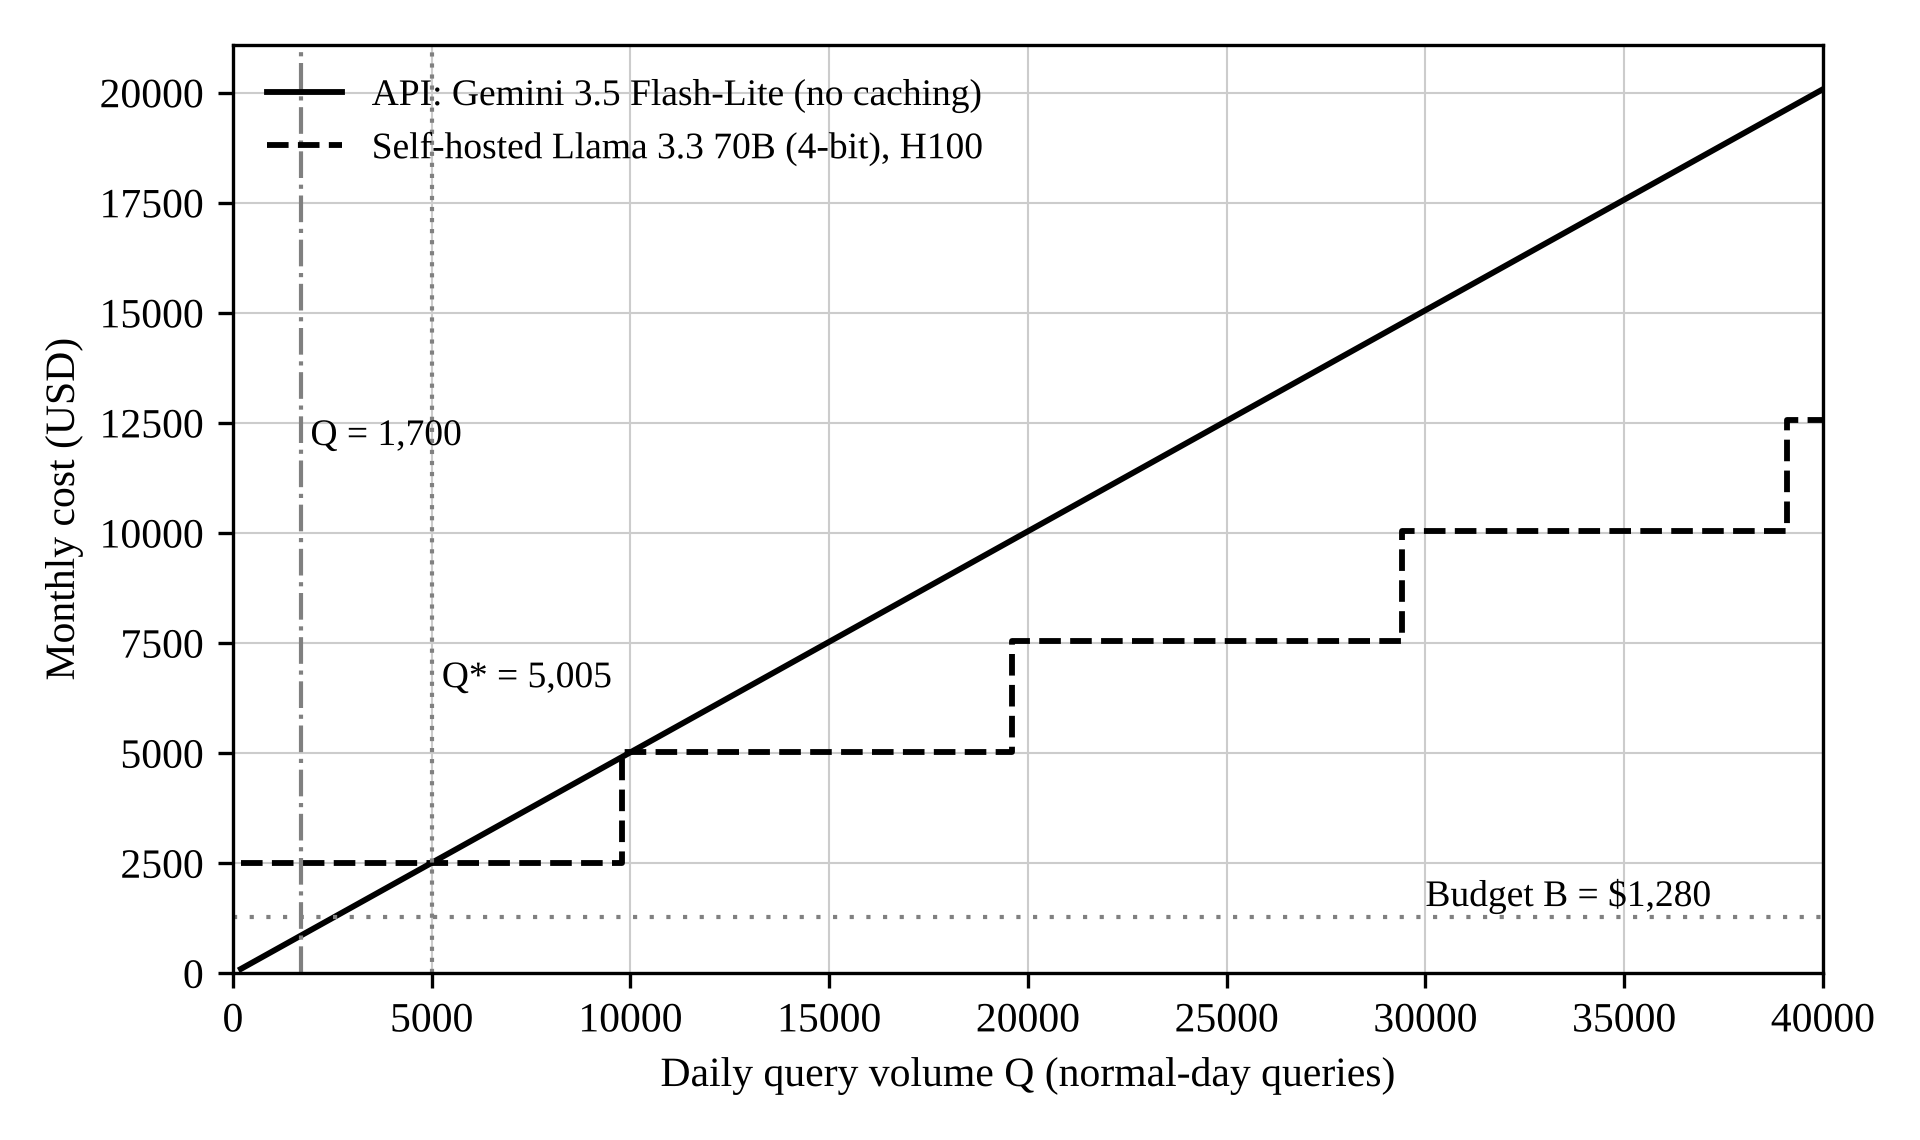

In [12]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = ["Liberation Serif", "DejaVu Serif"]
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(vols, api_line, color="black", linestyle="-", linewidth=1.4, label=f"API: {lower_latency} (no caching)")
ax.step(vols, self_line, where="post", color="black", linestyle="--", linewidth=1.4, label="Self-hosted Llama 3.3 70B (4-bit), H100")
ax.axvline(qstar_exact, color="gray", linestyle=":", linewidth=1)
ax.annotate(f"Q* = {qstar_exact:,.0f}", (qstar_exact, 6500), fontsize=9, ha="left", xytext=(qstar_exact+250, 6500))
ax.axvline(Q, color="gray", linestyle="-.", linewidth=1)
ax.annotate(f"Q = {Q:,}", (Q, 12000), fontsize=9, ha="left", xytext=(Q+250, 12000))
ax.axhline(B, color="gray", linestyle=(0, (1, 3)), linewidth=1)
ax.annotate(f"Budget B = ${B:,}", (30000, B), fontsize=9, ha="left", xytext=(30000, B+250))
ax.set_xlabel("Daily query volume Q (normal-day queries)")
ax.set_ylabel("Monthly cost (USD)")
ax.set_xlim(0, 40000); ax.set_ylim(0, max(api_line)*1.05)
ax.grid(True, color="#cccccc", linewidth=0.5)
ax.legend(frameon=False, fontsize=9, loc="upper left")
fig.tight_layout()
fig.savefig("cost_vs_volume.png", dpi=300)
print("saved plot")
from IPython.display import Image, display
display(Image("cost_vs_volume.png"))

## 12. Export results

In [13]:
out = dict(params=dict(R=R,D=D,Q=Q,N=N,p=p,H=H,B=B,T=T),
           tokens=dict(base_in=base_in, base_out=base_out, retry_in=retry_in, retry_out=retry_out, E_in=E_in, E_out=E_out,
                       E_calls=E_calls, E_prefix=E_prefix, queries_month=queries_month, M_in=M_in, M_out=M_out),
           peak=dict(q_heat_day=q_heat_day, peak_queries=peak_queries, qpm=peak_qpm, rpm=peak_llm_rpm, in_tpm=peak_in_tpm, out_tpm=peak_out_tpm),
           memory=dict(w_fp16=w_fp16, w_int8=w_int8, w_int4=w_int4, seq_len=seq_len, kv_per_token=kv_per_token, kv_per_seq=kv_per_seq,
                       usable=usable, free_for_kv=free_for_kv, max_seq=max_seq, gpu_month=GPU_MONTH, q_per_gpu=q_per_gpu),
           breakeven=dict(per_query=pq, qstar=qstar_exact),
           models=M)
json.dump(out, open("results.json","w"), indent=1, default=str)
print("results.json written")

results.json written
